In [1]:
import pandas as pd
import numpy as np


# 1. Càrrega de dades

In [2]:
movies_dataset = pd.read_csv("../data/movies.csv")
ratings_dataset = pd.read_csv("../data/ratings.csv")

In [3]:
movies_dataset.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
movies_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


In [5]:
movies_dataset.describe()

,movieId
count,9742.000000
mean,42200.353623
std,52160.494854
min,1.000000
25%,3248.250000
50%,7300.000000
75%,76232.000000
max,193609.000000


## 1.1. One-hot encoding genres i Extracció Títol i aka

In [6]:
# Extraiem l'any i el posem en una nova columna
if 'year' not in movies_dataset.columns:
    movies_dataset['year'] = movies_dataset['title'].str.extract(r'\((\d{4})!\)')
    movies_dataset['title'] = movies_dataset['title'].str.replace(r'\(\d{4}\)', '', regex=True).str.strip()

# Extraiem el títol alternatiu i el posem en una nova columna: "City of Lost Children, The (Cité des enfants perdus, La)"
if 'aka' not in movies_dataset.columns:
    movies_dataset['aka'] = movies_dataset['title'].str.extract(r'\((.*?)\)')
    movies_dataset['title'] = movies_dataset['title'].str.replace(r'\(.*?\)', '', regex=True).str.strip()

# Fem un one-hot encoding a genres
movies_dataset_one_hot = pd.concat([movies_dataset, movies_dataset['genres'].str.get_dummies(sep="|")], axis=1)

In [7]:
movies_dataset_one_hot.head()

,movieId,title,genres,year,aka,(no genres listed),Action,Adventure,Animation,Children,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,NaN,NaN,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji,Adventure|Children|Fantasy,NaN,NaN,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men,Comedy|Romance,NaN,NaN,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale,Comedy|Drama|Romance,NaN,NaN,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II,Comedy,NaN,NaN,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
#save csv 
movies_dataset_one_hot.to_csv("../data/movies_one_hot.csv", index=False)
movies_dataset = movies_dataset_one_hot

In [9]:
ratings_dataset.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [10]:
ratings_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [11]:
ratings_dataset.describe()

,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [12]:
ratings_dataset.sort_values('timestamp')

,userId,movieId,rating,timestamp
66719,429,595,5.0,828124615
66716,429,588,5.0,828124615
66717,429,590,5.0,828124615
66718,429,592,5.0,828124615
66712,429,432,3.0,828124615
...,...,...,...,...
81475,514,187031,2.5,1537674927
81477,514,187595,3.0,1537674946
81336,514,5247,2.5,1537757040
81335,514,5246,1.5,1537757059


In [13]:
ratings_dataset['userId'].nunique()

610

# 2. Divisió train/test

In [14]:
users = ratings_dataset['userId'].unique()

train_list = []
test_list = []

for i in range(users.shape[0]):
    ratings_subset = ratings_dataset.loc[ratings_dataset['userId'] == users[i]].sort_values('timestamp')
    limit = max(1, int(ratings_subset.shape[0] * 0.8))
    
    train_list.append(ratings_subset.iloc[:limit])
    test_list.append(ratings_subset.iloc[limit:])

ratings_train_set = pd.concat(train_list, ignore_index=True)
ratings_test_set = pd.concat(test_list, ignore_index=True)

ratings_train_set.to_csv("../data/train_set.csv", index=False)
ratings_test_set.to_csv("../data/test_set.csv", index=False)

movies_train_set = movies_dataset[movies_dataset['movieId'].isin(ratings_train_set['movieId'])]
movies_test_set = movies_dataset[movies_dataset['movieId'].isin(ratings_test_set['movieId'])]

movies_train_set.to_csv("../data/movies_train_set.csv", index=False)
movies_test_set.to_csv("../data/movies_test_set.csv", index=False)

Crearem ara P i Q en base a les mides que havem de definit com a training set i test set.

# 3. Entrenament

Epoch 1/20 - Train MSE: 0.9227
Epoch 2/20 - Train MSE: 0.8265
Epoch 3/20 - Train MSE: 0.7906
Epoch 4/20 - Train MSE: 0.7679
Epoch 5/20 - Train MSE: 0.7513
Epoch 6/20 - Train MSE: 0.7379
Epoch 7/20 - Train MSE: 0.7266
Epoch 8/20 - Train MSE: 0.7166
Epoch 9/20 - Train MSE: 0.7075
Epoch 10/20 - Train MSE: 0.6988
Epoch 11/20 - Train MSE: 0.6906
Epoch 12/20 - Train MSE: 0.6826
Epoch 13/20 - Train MSE: 0.6746
Epoch 14/20 - Train MSE: 0.6663
Epoch 15/20 - Train MSE: 0.6579
Epoch 16/20 - Train MSE: 0.6492
Epoch 17/20 - Train MSE: 0.6401
Epoch 18/20 - Train MSE: 0.6303
Epoch 19/20 - Train MSE: 0.6203
Epoch 20/20 - Train MSE: 0.6097


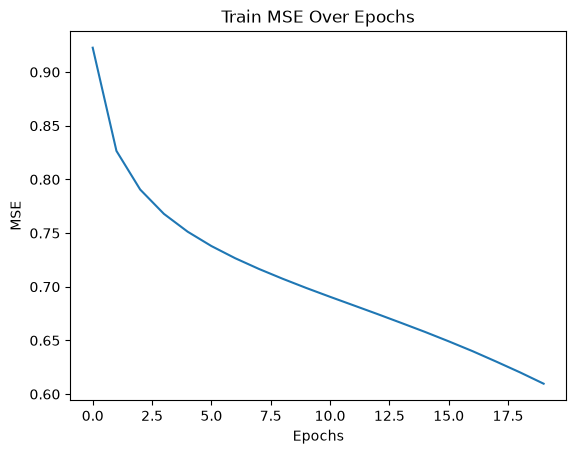

In [15]:
k = 20
epochs = 20
lambda_ = 0.02
lr = 0.005

# 1. Creació dels mapatges d'índexs únics
unique_users = ratings_train_set['userId'].unique()
unique_movies = ratings_train_set['movieId'].unique()

user2idx = {user_id: idx for idx, user_id in enumerate(unique_users)}
movie2idx = {movie_id: idx for idx, movie_id in enumerate(unique_movies)}

n_users = len(unique_users)
n_movies = len(unique_movies)

# 2. Inicialització de paràmetres amb les mides reals
mu = ratings_train_set['rating'].mean()
b_u = np.zeros(n_users)
b_i = np.zeros(n_movies)
P = np.random.normal(0, 0.1, (n_users, k))
Q = np.random.normal(0, 0.1, (n_movies, k))

# Extract Data Arrays per a màxim rendiment
users_arr = ratings_train_set['userId'].map(user2idx).to_numpy()
movies_arr = ratings_train_set['movieId'].map(movie2idx).to_numpy()
ratings_arr = ratings_train_set['rating'].to_numpy()

n_samples = len(ratings_arr)

train_mse_list = []

# 3. Bucle d'entrenament
for epoch in range(epochs):
    # Permutació d'índexs per fer el shuffle súper ràpid
    indices = np.random.permutation(n_samples)
    
    epoch_loss = 0

    for idx in indices:
        u = users_arr[idx]
        i = movies_arr[idx]
        r_ui = ratings_arr[idx]

        # Predicció i error
        r_ui_barret = mu + b_u[u] + b_i[i] + np.dot(P[u], Q[i])
        e_ui = r_ui - r_ui_barret

        # Guardem còpia del vector original abans d'actualitzar P
        P_u_old = P[u].copy()

        # Actualització amb SGD
        b_u[u] += lr * (e_ui - lambda_ * b_u[u])
        b_i[i] += lr * (e_ui - lambda_ * b_i[i])
        P[u] += lr * (e_ui * Q[i] - lambda_ * P_u_old)
        Q[i] += lr * (e_ui * P_u_old - lambda_ * Q[i])

        # Acumular error quadràtic pur (MSE)
        epoch_loss += e_ui ** 2

    train_mse = epoch_loss / n_samples
    train_mse_list.append(train_mse)
    print(f'Epoch {epoch + 1}/{epochs} - Train MSE: {train_mse:.4f}')

import matplotlib.pyplot as plt

plt.plot(train_mse_list)
plt.title('Train MSE Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.show()

# 4. Predicció

In [16]:
def predict_rating(user_id, movie_id):
    u = user2idx.get(user_id, -1)
    i = movie2idx.get(movie_id, -1)

    if u == -1:         # user cold start (user not found in training set)
        return None
    if i == -1:         # item cold start (item not found in training set)
        return None

    prediction = mu + b_u[u] + b_i[i] + P[u].dot(Q[i])

    if prediction < 0.5:
        prediction = 0.5
    elif prediction > 5:
        prediction = 5
    return prediction

# 5. Recomanació

In [17]:
user_id = 1

seen_movies = ratings_train_set.loc[ratings_train_set['userId'] == user_id, 'movieId'].tolist()

predictions_not_seen = []

for i in range(n_movies):
    if unique_movies[i] not in seen_movies:
        predictions_not_seen.append((unique_movies[i], predict_rating(user_id, unique_movies[i])))

predictions_not_seen.sort(key=lambda x: x[1], reverse=True)
predicted_top_5 = predictions_not_seen[:5]
predicted_top_5

[(np.int64(318), 5),
 (np.int64(2959), 5),
 (np.int64(1250), 5),
 (np.int64(1225), 5),
 (np.int64(593), 5)]

# 6. Historial

In [18]:
def get_user_history(user_id):
    """
    Get the history of movies rated by a specific user, including movie titles and genres, sorted by rating in descending order.
    Parameters:
    user_id (int): The ID of the user whose history is to be retrieved.
    Returns:
    pd.DataFrame: A DataFrame containing the movieId, title, genres, and rating of the movies rated by the user, sorted by rating in descending order.
    """
    user_history = ratings_train_set.loc[ratings_train_set['userId'] == user_id]
    user_history = user_history.merge(movies_dataset, on='movieId', how='left')
    user_history = user_history.sort_values(by='rating', ascending=False)
    return user_history[['movieId', 'title', 'genres', 'rating']]

In [19]:
get_user_history(1)

,movieId,title,genres,rating
0,1210,Star Wars: Episode VI - Return of the Jedi,Action|Adventure|Sci-Fi,5.0
69,1196,Star Wars: Episode V - The Empire Strikes Back,Action|Adventure|Sci-Fi,5.0
130,362,"Jungle Book, The",Adventure|Children|Romance,5.0
124,2115,Indiana Jones and the Temple of Doom,Action|Adventure|Fantasy,5.0
120,2987,Who Framed Roger Rabbit?,Adventure|Animation|Children|Comedy|Crime|Fant...,5.0
...,...,...,...,...
102,316,Stargate,Action|Adventure|Sci-Fi,3.0
20,3243,Encino Man,Comedy,3.0
179,2389,Psycho,Crime|Horror|Thriller,2.0
131,2617,"Mummy, The",Action|Adventure|Comedy|Fantasy|Horror|Thriller,2.0


# 7. Avaluació

## 7.1. RMSE i MAE

In [20]:
ratings_test_set
movies_test_set
ratings_test_set_predictions = []

rmse = 0
mae = 0


for index, row in ratings_test_set.iterrows():
    user_id = row['userId']
    movie_id = row['movieId']
    predicted_rating = predict_rating(user_id, movie_id)
    actual_rating = row['rating']

    if predicted_rating is None:
        continue  # Skip if the user or movie is not in the training set

    rmse += (predicted_rating - actual_rating) ** 2
    mae += abs(predicted_rating - actual_rating)


    ratings_test_set_predictions.append(predicted_rating)

n_valid_predictions = len(ratings_test_set_predictions)
rmse = (rmse / n_valid_predictions) ** 0.5
mae = mae / n_valid_predictions

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

RMSE: 0.8868
MAE: 0.6807


## 7.2. NDCG@10

### Càlcul de NDCG@10

Per a cada usuari, s'avaluen les pel·lícules del conjunt de test que el model pot predir. Les pel·lícules es ordenen de més a menys segons la puntuació predita, i es calcula el **DCG** de les 10 primeres:

- La rellevància és gradual i es calcula a partir de la puntuació real: $2^{r}-1$, on $r$ és la puntuació donada per l'usuari.
- Cada rellevància es divideix per un descompte logarítmic, $\log_2(j+1)$, on $j$ és la posició de la pel·lícula (començant per 1). Així, les rellevàncies de les primeres posicions tenen més pes.
- El **IDCG** és el DCG ideal: el valor que s'obtindria ordenant les pel·lícules segons les seves puntuacions reals.

La mètrica de cada usuari és $NDCG@10 = DCG@10 / IDCG@10$. Finalment, es calcula la mitjana dels NDCG dels usuaris amb prediccions vàlides. El resultat està entre 0 i 1; com més a prop d'1, millor és l'ordre de les recomanacions.

In [21]:
k = 10

def ndcg_at_k(actual_ratings, predicted_ratings, k=10):
    actual_ratings = np.asarray(actual_ratings, dtype=float)
    predicted_ratings = np.asarray(predicted_ratings, dtype=float)

    if len(actual_ratings) == 0:
        return np.nan

    # Graded relevance gain
    gains = (2 ** actual_ratings) - 1
    discounts = np.log2(np.arange(2, len(actual_ratings) + 2))

    ranked_indices = np.argsort(predicted_ratings)[::-1][:k]
    ideal_indices = np.argsort(gains)[::-1][:k]

    dcg = np.sum(gains[ranked_indices] / discounts[:len(ranked_indices)])
    idcg = np.sum(gains[ideal_indices] / discounts[:len(ideal_indices)])

    return dcg / idcg if idcg > 0 else 0.0


user_ndcg = []

for user_id, group in ratings_test_set.groupby("userId"):
    valid_actual = []
    valid_predictions = []

    for row in group.itertuples(index=False):
        prediction = predict_rating(row.userId, row.movieId)
        if prediction is not None:
            valid_actual.append(row.rating)
            valid_predictions.append(prediction)

    if valid_actual:
        user_ndcg.append(ndcg_at_k(valid_actual, valid_predictions, k))

mean_ndcg = np.mean(user_ndcg) if user_ndcg else np.nan
print(f"NDCG@{k}: {mean_ndcg:.4f}")

NDCG@10: 0.7885
